In [6]:
from pathlib import Path

import pandas as pd

PASTA_DADOS = Path("dados")
SEPARADOR = ";"
SEPARADOR_DECIMAL = ","
CODIFICACOES = ("utf-8", "latin-1")

COLUNA_DATA = "Data da Coleta"
COLUNA_PRECO = "Valor de Venda"
COLUNA_PRODUTO = "Produto"
COLUNA_ESTADO = "Estado - Sigla"
COLUNA_ORIGEM = "arquivo_origem"

In [7]:
def ler_arquivo_csv(caminho: Path) -> pd.DataFrame:
    for codificacao in CODIFICACOES:
        try:
            tabela = pd.read_csv(
                caminho,
                sep=SEPARADOR,
                decimal=SEPARADOR_DECIMAL,
                encoding=codificacao,
            )
            tabela.columns = tabela.columns.str.strip()
            tabela[COLUNA_ORIGEM] = caminho.name
            return tabela
        except UnicodeDecodeError:
            continue
    raise ValueError(f"Não foi possível ler o arquivo: {caminho.name}")


def listar_arquivos(pasta: Path) -> list[Path]:
    arquivos = sorted(pasta.glob("*.csv"))
    if not arquivos:
        raise FileNotFoundError(f"Nenhum CSV encontrado em: {pasta.resolve()}")
    return arquivos


def verificar_colunas(tabelas: list[pd.DataFrame]) -> None:
    colunas_base = set(tabelas[0].columns)
    for tabela in tabelas[1:]:
        diferencas = colunas_base.symmetric_difference(tabela.columns)
        if diferencas:
            arquivo = tabela[COLUNA_ORIGEM].iloc[0]
            print(f"Atenção: colunas diferentes em {arquivo}: {diferencas}")


def carregar_dados(pasta: Path) -> pd.DataFrame:
    tabelas = [ler_arquivo_csv(caminho) for caminho in listar_arquivos(pasta)]
    verificar_colunas(tabelas)
    return pd.concat(tabelas, ignore_index=True)

In [8]:
dados = carregar_dados(PASTA_DADOS)
print(f"Arquivos lidos: {dados[COLUNA_ORIGEM].nunique()}")
print(f"Linhas: {dados.shape[0]:,} | Colunas: {dados.shape[1]}")

Arquivos lidos: 6
Linhas: 2,624,773 | Colunas: 17


In [9]:
def mostrar_estrutura(tabela: pd.DataFrame) -> None:
    tabela.info()


def mostrar_ausentes(tabela: pd.DataFrame) -> None:
    ausentes = tabela.isna().sum()
    percentual = (ausentes / len(tabela) * 100).round(2)
    resumo = pd.DataFrame({"ausentes": ausentes, "percentual (%)": percentual})
    print(resumo[resumo["ausentes"] > 0].sort_values("ausentes", ascending=False))


def mostrar_estatisticas_preco(tabela: pd.DataFrame) -> None:
    print(tabela[COLUNA_PRECO].describe().round(2))


def mostrar_categorias(tabela: pd.DataFrame, coluna: str) -> None:
    print(tabela[coluna].value_counts())


def mostrar_periodo(tabela: pd.DataFrame) -> None:
    datas = pd.to_datetime(tabela[COLUNA_DATA], format="%d/%m/%Y", errors="coerce")
    print(f"Primeira coleta: {datas.min():%d/%m/%Y}")
    print(f"Última coleta:   {datas.max():%d/%m/%Y}")
    print(f"Datas inválidas: {datas.isna().sum()}")


def contar_duplicados(tabela: pd.DataFrame) -> None:
    print(f"Linhas duplicadas: {tabela.duplicated().sum():,}")

In [10]:
mostrar_estrutura(dados)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2624773 entries, 0 to 2624772
Data columns (total 17 columns):
 #   Column             Dtype  
---  ------             -----  
 0   Regiao - Sigla     object 
 1   Estado - Sigla     object 
 2   Municipio          object 
 3   Revenda            object 
 4   CNPJ da Revenda    object 
 5   Nome da Rua        object 
 6   Numero Rua         object 
 7   Complemento        object 
 8   Bairro             object 
 9   Cep                object 
 10  Produto            object 
 11  Data da Coleta     object 
 12  Valor de Venda     float64
 13  Valor de Compra    float64
 14  Unidade de Medida  object 
 15  Bandeira           object 
 16  arquivo_origem     object 
dtypes: float64(2), object(15)
memory usage: 340.4+ MB


In [11]:
mostrar_ausentes(dados)

                 ausentes  percentual (%)
Valor de Compra   2104720           80.19
Complemento       1999642           76.18
Bairro               7339            0.28
Numero Rua           1377            0.05


In [12]:
mostrar_estatisticas_preco(dados)

count    2624773.00
mean           4.60
std            1.26
min            1.70
25%            3.59
50%            4.46
75%            5.59
max            9.79
Name: Valor de Venda, dtype: float64


In [13]:
mostrar_categorias(dados, COLUNA_PRODUTO)

Produto
GASOLINA              732792
ETANOL                644921
DIESEL S10            577763
DIESEL                366500
GASOLINA ADITIVADA    256706
GNV                    46091
Name: count, dtype: int64


In [14]:
mostrar_categorias(dados, COLUNA_ESTADO)

Estado - Sigla
SP    756068
MG    266459
RJ    202194
PR    169445
RS    165053
BA    148750
SC    107498
GO     99392
CE     97079
PE     80135
MT     67662
ES     49599
PA     47590
MA     46775
MS     40014
RN     32352
PB     31380
RO     31230
PI     30903
AM     29766
AL     28153
DF     23942
TO     22045
SE     19168
AC     17519
AP      7517
RR      7085
Name: count, dtype: int64


In [15]:
mostrar_periodo(dados)

Primeira coleta: 03/07/2017
Última coleta:   29/12/2023
Datas inválidas: 0


In [16]:
contar_duplicados(dados)

Linhas duplicadas: 0


In [17]:
def contar_registros_por_mes(tabela: pd.DataFrame) -> pd.Series:
    datas = pd.to_datetime(tabela[COLUNA_DATA], format="%d/%m/%Y", errors="coerce")
    return datas.dt.to_period("M").value_counts().sort_index()


print(dados[COLUNA_ORIGEM].value_counts().sort_index())
print(contar_registros_por_mes(dados))

arquivo_origem
Preços semestrais - AUTOMOTIVOS_2023.02.csv    472424
ca-2017-02.csv                                 300947
ca-2018-02.csv                                 493169
ca-2019-02.csv                                 507299
ca-2021-02.csv                                 472856
ca-2022-02.csv                                 378078
Name: count, dtype: int64
Data da Coleta
2017-07     77501
2017-08     48788
2017-09     41105
2017-10     50458
2017-11     42065
2017-12     41030
2018-07     83517
2018-08     86886
2018-09     76002
2018-10     90805
2018-11     79977
2018-12     75982
2019-07     92202
2019-08     79527
2019-09     82545
2019-10     89666
2019-11     76667
2019-12     86692
2021-07     71899
2021-08     80887
2021-09     77417
2021-10     74244
2021-11     85609
2021-12     82800
2022-07     87362
2022-08    105488
2022-09     48228
2022-10     33489
2022-11     51423
2022-12     52088
2023-07     80860
2023-08     82925
2023-09     72251
2023-10     85300
2023-11 

In [18]:
import matplotlib.pyplot as plt

# Configurações da análise
PRODUTO_ANALISADO = "GASOLINA"
MESES_ANALISE = [7, 8, 9, 10]
ANOS_ELEITORAIS = [2018, 2022]
NOMES_MESES = {7: "Jul", 8: "Ago", 9: "Set", 10: "Out"}
COR_POR_ANO = {
    2017: "#2ca02c",  # verde
    2018: "#d62728",  # vermelho (eleição)
    2019: "#ff7f0e",  # laranja
    2021: "#9467bd",  # roxo
    2022: "#1f77b4",  # azul (eleição)
    2023: "#17becf",  # turquesa
}


def filtrar_gasolina(tabela: pd.DataFrame) -> pd.DataFrame:
    produto = tabela[COLUNA_PRODUTO].str.strip().str.upper()
    gasolina = tabela[produto == PRODUTO_ANALISADO].copy()

    if gasolina.empty:
        disponiveis = sorted(produto.dropna().unique())
        raise ValueError(
            f"Produto '{PRODUTO_ANALISADO}' não encontrado. Disponíveis: {disponiveis}"
        )

    gasolina["data"] = pd.to_datetime(
        gasolina[COLUNA_DATA], format="%d/%m/%Y", errors="coerce"
    )
    gasolina = gasolina.dropna(subset=["data", COLUNA_PRECO])
    gasolina["ano"] = gasolina["data"].dt.year
    gasolina["mes"] = gasolina["data"].dt.month

    return gasolina[gasolina["mes"].isin(MESES_ANALISE)]


def calcular_preco_medio_mensal(gasolina: pd.DataFrame) -> pd.DataFrame:
    return gasolina.pivot_table(
        index="mes", columns="ano", values=COLUNA_PRECO, aggfunc="mean"
    )


def calcular_variacao_sobre_julho(preco_mensal: pd.DataFrame) -> pd.DataFrame:
    return (preco_mensal / preco_mensal.loc[MESES_ANALISE[0]] - 1) * 100


def plotar_linhas(tabela: pd.DataFrame, titulo: str, rotulo_y: str) -> None:

    _, eixo = plt.subplots(figsize=(10, 6))

    for ano in tabela.columns:
        eleitoral = ano in ANOS_ELEITORAIS
        eixo.plot(
            tabela.index,
            tabela[ano],
            marker="o",
            linewidth=3 if eleitoral else 1.5,
            linestyle="-" if eleitoral else "--",
            color=COR_POR_ANO[ano],
            label=f"{ano} (eleição)" if eleitoral else str(ano),
        )

    eixo.set_xticks(MESES_ANALISE)
    eixo.set_xticklabels([NOMES_MESES[mes] for mes in MESES_ANALISE])
    eixo.set_title(titulo)
    eixo.set_xlabel("Mês")
    eixo.set_ylabel(rotulo_y)
    eixo.grid(alpha=0.3)
    eixo.legend(title="Ano")
    plt.tight_layout()
    plt.show()

    eixo.set_xticks(MESES_ANALISE)
    eixo.set_xticklabels([NOMES_MESES[mes] for mes in MESES_ANALISE])
    eixo.set_title(titulo)
    eixo.set_xlabel("Mês")
    eixo.set_ylabel(rotulo_y)
    eixo.grid(alpha=0.3)
    eixo.legend(title="Ano")
    plt.tight_layout()
    plt.show()

ano   2017   2018   2019   2021   2022   2023
mes                                          
7    3.607  4.536  4.394  5.800  6.059  5.609
8    3.815  4.489  4.363  5.921  5.424  5.713
9    3.900  4.655  4.370  6.084  5.034  5.840
10   3.923  4.754  4.418  6.337  4.864  5.765


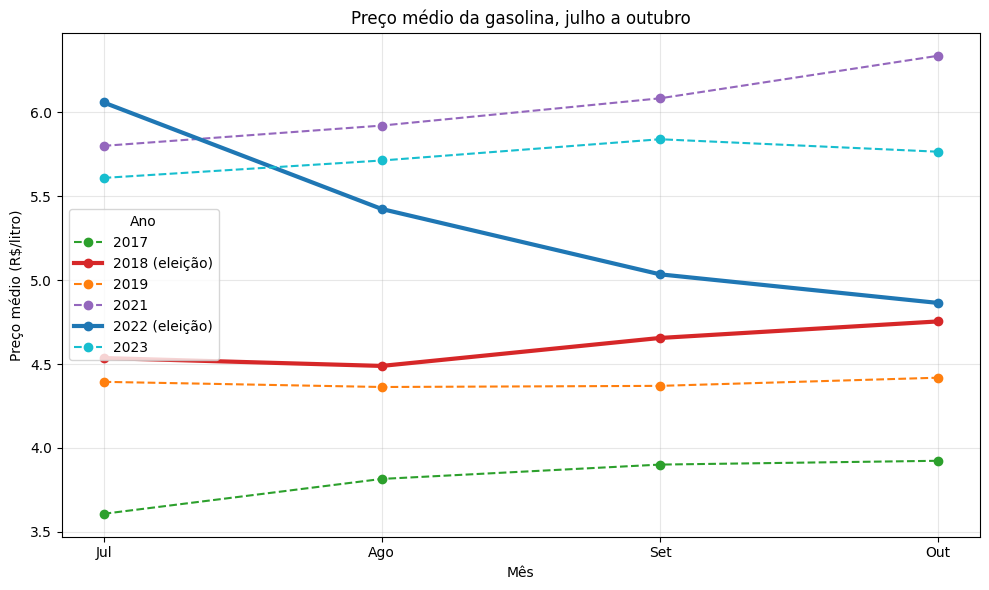

<Figure size 640x480 with 0 Axes>

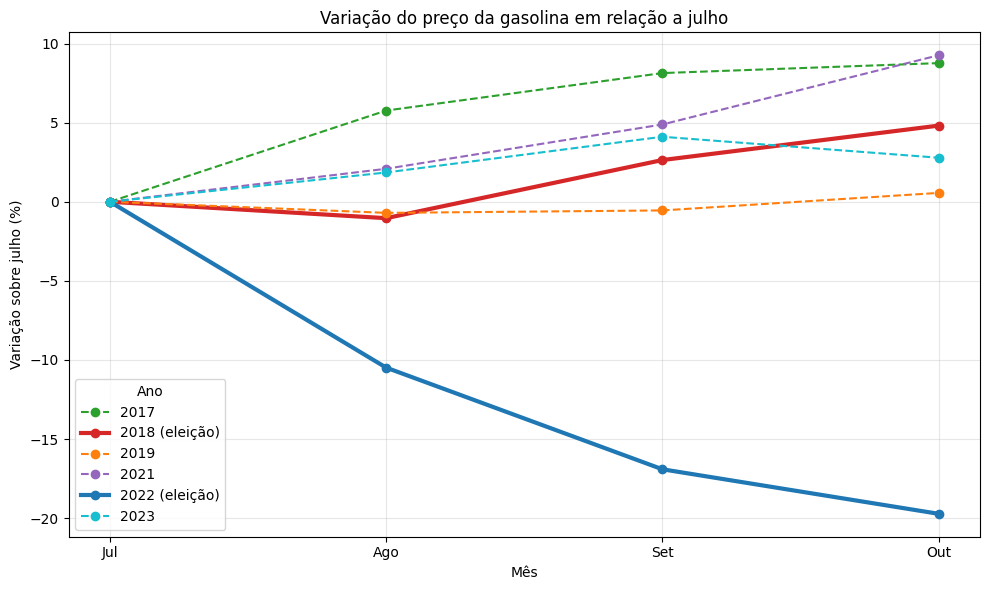

<Figure size 640x480 with 0 Axes>

In [19]:
gasolina = filtrar_gasolina(dados)
preco_mensal = calcular_preco_medio_mensal(gasolina)
print(preco_mensal.round(3))

plotar_linhas(
    preco_mensal,
    "Preço médio da gasolina, julho a outubro",
    "Preço médio (R$/litro)",
)

variacao = calcular_variacao_sobre_julho(preco_mensal)
plotar_linhas(
    variacao,
    "Variação do preço da gasolina em relação a julho",
    "Variação sobre julho (%)",
)

In [20]:
COLUNA_CNPJ = "CNPJ da Revenda"
COLUNA_MUNICIPIO = "Municipio"
MES_ELEICAO = 10

# Colunas que serão mantidas. As demais (endereço, complemento, valor de compra etc.) saem.
COLUNAS_MANTIDAS = [
    "Regiao - Sigla", COLUNA_ESTADO, COLUNA_MUNICIPIO, COLUNA_CNPJ,
    COLUNA_PRODUTO, COLUNA_DATA, COLUNA_PRECO, "Bandeira", COLUNA_ORIGEM,
]


def registrar_etapa(registro: list, etapa: str, linhas_antes: int,
                    linhas_depois: int, justificativa: str) -> None:

    registro.append({
        "etapa": etapa,
        "linhas_antes": linhas_antes,
        "linhas_depois": linhas_depois,
        "removidas": linhas_antes - linhas_depois,
        "justificativa": justificativa,
    })


def filtrar_produto(tabela: pd.DataFrame) -> pd.DataFrame:

    produto = tabela[COLUNA_PRODUTO].str.strip().str.upper()
    return tabela[produto == PRODUTO_ANALISADO].copy()


def converter_tipos(tabela: pd.DataFrame) -> pd.DataFrame:

    tabela = tabela.copy()
    tabela["data"] = pd.to_datetime(
        tabela[COLUNA_DATA], format="%d/%m/%Y", errors="coerce"
    )
    tabela[COLUNA_PRECO] = pd.to_numeric(tabela[COLUNA_PRECO], errors="coerce")
    for coluna in (COLUNA_ESTADO, COLUNA_MUNICIPIO):
        tabela[coluna] = tabela[coluna].str.strip().str.upper()
    return tabela


def filtrar_meses(tabela: pd.DataFrame) -> pd.DataFrame:

    return tabela[tabela["data"].dt.month.isin(MESES_ANALISE)].copy()


def remover_ausentes(tabela: pd.DataFrame) -> pd.DataFrame:

    return tabela.dropna(subset=["data", COLUNA_PRECO, COLUNA_CNPJ]).copy()


def remover_duplicados(tabela: pd.DataFrame) -> pd.DataFrame:

    return tabela.drop_duplicates(subset=[COLUNA_CNPJ, "data"], keep="first").copy()


def adicionar_colunas_analise(tabela: pd.DataFrame) -> pd.DataFrame:

    tabela = tabela.copy()
    tabela["ano"] = tabela["data"].dt.year
    tabela["mes"] = tabela["data"].dt.month
    tabela["periodo"] = (
        tabela["mes"].eq(MES_ELEICAO).map({True: "Eleição", False: "Pré-eleição"})
    )
    tabela["tipo_ano"] = (
        tabela["ano"].isin(ANOS_ELEITORAIS).map({True: "Eleitoral", False: "Controle"})
    )
    return tabela


def limpar_dados(dados: pd.DataFrame) -> tuple[pd.DataFrame, pd.DataFrame]:

    registro = []
    tabela = dados[COLUNAS_MANTIDAS].copy()

    etapas = [
        ("Filtrar gasolina comum", filtrar_produto,
         "A análise é restrita à gasolina comum."),
        ("Converter tipos e padronizar texto", converter_tipos,
         "Data e preço precisam ter o tipo correto para os cálculos."),
        ("Filtrar julho a outubro", filtrar_meses,
         "Janela de pré-eleição (jul-set) e eleição (out)."),
        ("Remover ausentes", remover_ausentes,
         "Sem data, preço ou posto não é possível analisar a linha."),
        ("Remover duplicados", remover_duplicados,
         "Mesmo posto e mesma data contam uma única vez."),
    ]
    for nome, funcao, justificativa in etapas:
        linhas_antes = len(tabela)
        tabela = funcao(tabela)
        registrar_etapa(registro, nome, linhas_antes, len(tabela), justificativa)

    return adicionar_colunas_analise(tabela), pd.DataFrame(registro)

In [21]:
gasolina, registro_limpeza = limpar_dados(dados)
print(registro_limpeza.to_string(index=False))
print(f"\nBase final: {gasolina.shape[0]:,} linhas")
gasolina.head()

                             etapa  linhas_antes  linhas_depois  removidas                                              justificativa
            Filtrar gasolina comum       2624773         732792    1891981                     A análise é restrita à gasolina comum.
Converter tipos e padronizar texto        732792         732792          0 Data e preço precisam ter o tipo correto para os cálculos.
           Filtrar julho a outubro        732792         502308     230484           Janela de pré-eleição (jul-set) e eleição (out).
                  Remover ausentes        502308         502308          0  Sem data, preço ou posto não é possível analisar a linha.
                Remover duplicados        502308         502308          0             Mesmo posto e mesma data contam uma única vez.

Base final: 502,308 linhas


,Regiao - Sigla,Estado - Sigla,Municipio,CNPJ da Revenda,Produto,Data da Coleta,Valor de Venda,Bandeira,arquivo_origem,data,ano,mes,periodo,tipo_ano
0,SE,SP,SOROCABA,00.003.188/0001-21,GASOLINA,03/07/2023,4.87,BRANCA,Preços semestrais - AUTOMOTIVOS_2023.02.csv,2023-07-03,2023,7,Pré-eleição,Controle
3,N,AC,CRUZEIRO DO SUL,03.608.766/0006-56,GASOLINA,03/07/2023,6.95,VIBRA ENERGIA,Preços semestrais - AUTOMOTIVOS_2023.02.csv,2023-07-03,2023,7,Pré-eleição,Controle
5,N,AC,CRUZEIRO DO SUL,01.492.748/0003-83,GASOLINA,03/07/2023,6.93,IPIRANGA,Preços semestrais - AUTOMOTIVOS_2023.02.csv,2023-07-03,2023,7,Pré-eleição,Controle
10,N,AC,RIO BRANCO,08.220.930/0001-62,GASOLINA,05/07/2023,6.29,VIBRA ENERGIA,Preços semestrais - AUTOMOTIVOS_2023.02.csv,2023-07-05,2023,7,Pré-eleição,Controle
15,N,AC,RIO BRANCO,01.198.443/0001-00,GASOLINA,05/07/2023,6.22,VIBRA ENERGIA,Preços semestrais - AUTOMOTIVOS_2023.02.csv,2023-07-05,2023,7,Pré-eleição,Controle


In [22]:
def resumir_preco(tabela: pd.DataFrame, agrupar_por: list) -> pd.DataFrame:

    return tabela.groupby(agrupar_por)[COLUNA_PRECO].agg(
        registros="count", media="mean", mediana="median",
        desvio="std", minimo="min", maximo="max",
    ).round(3)


def resumir_amostra(tabela: pd.DataFrame) -> pd.DataFrame:

    return tabela.groupby(["ano", "mes"]).agg(
        registros=(COLUNA_PRECO, "size"),
        postos=(COLUNA_CNPJ, "nunique"),
        municipios=(COLUNA_MUNICIPIO, "nunique"),
    )


def listar_precos_extremos(tabela: pd.DataFrame) -> pd.DataFrame:

    grupos = tabela.groupby(["ano", "mes"])[COLUNA_PRECO]
    q1 = grupos.transform("quantile", 0.25)
    q3 = grupos.transform("quantile", 0.75)
    amplitude = q3 - q1
    extremos = (
        (tabela[COLUNA_PRECO] < q1 - 3 * amplitude)
        | (tabela[COLUNA_PRECO] > q3 + 3 * amplitude)
    )
    return tabela[extremos]


def calcular_preco_mensal(tabela: pd.DataFrame, estatistica: str) -> pd.DataFrame:

    return tabela.pivot_table(
        index="mes", columns="ano", values=COLUNA_PRECO, aggfunc=estatistica
    )

In [23]:
print("Estatísticas do preço por ano e período:")
print(resumir_preco(gasolina, ["ano", "periodo"]))

Estatísticas do preço por ano e período:
                  registros  media  mediana  desvio  minimo  maximo
ano  periodo                                                       
2017 Eleição          15373  3.923    3.899   0.250   3.199   5.200
     Pré-eleição      50723  3.740    3.750   0.308   2.799   5.200
2018 Eleição          27717  4.754    4.760   0.279   3.899   6.290
     Pré-eleição      75237  4.556    4.560   0.305   3.649   6.290
2019 Eleição          27203  4.418    4.399   0.303   3.629   5.799
     Pré-eleição      77271  4.376    4.380   0.312   3.559   5.859
2021 Eleição          18692  6.337    6.299   0.402   4.690   7.889
     Pré-eleição      58265  5.938    5.899   0.371   4.549   7.236
2022 Eleição           8849  4.864    4.860   0.279   3.490   7.340
     Pré-eleição      60495  5.576    5.550   0.567   4.130   8.750
2023 Eleição          21858  5.765    5.710   0.396   4.590   7.620
     Pré-eleição      60625  5.716    5.690   0.401   4.490   7.620


In [24]:
print("Amostra por ano e mês:")
print(resumir_amostra(gasolina))

Amostra por ano e mês:
          registros  postos  municipios
ano  mes                               
2017 7        23377    8906         511
     8        14838    7390         465
     9        12508    7232         463
     10       15373    7585         464
2018 7        25550    9647         462
     8        26544    9844         462
     9        23143    9544         461
     10       27717    9697         461
2019 7        28070   10145         460
     8        24153    9988         460
     9        25048   10210         462
     10       27203   10256         461
2021 7        18134    8074         369
     8        20490    8295         381
     9        19641    8077         384
     10       18692    7978         377
2022 7        21917    8793         460
     8        26424    9222         460
     9        12154    7654         452
     10        8849    4173         200
2023 7        20770    6797         460
     8        21321    6730         460
     9        185

In [25]:
extremos = listar_precos_extremos(gasolina)
print(f"Preços extremos encontrados: {len(extremos)}")
extremos[["ano", "mes", COLUNA_ESTADO, COLUNA_MUNICIPIO, COLUNA_PRECO]].head(20)

Preços extremos encontrados: 279


,ano,mes,Estado - Sigla,Municipio,Valor de Venda
6383,2023,7,SP,SAO PAULO,7.39
7225,2023,7,AM,TEFE,7.30
7227,2023,7,AM,TEFE,7.29
7228,2023,7,AM,TEFE,7.30
12478,2023,7,AM,TEFE,7.29
12951,2023,7,AM,TEFE,7.29
13936,2023,7,AM,TEFE,7.29
24826,2023,7,SP,SAO PAULO,7.29
29574,2023,7,SP,SAO PAULO,7.29
30548,2023,7,AM,TEFE,7.29


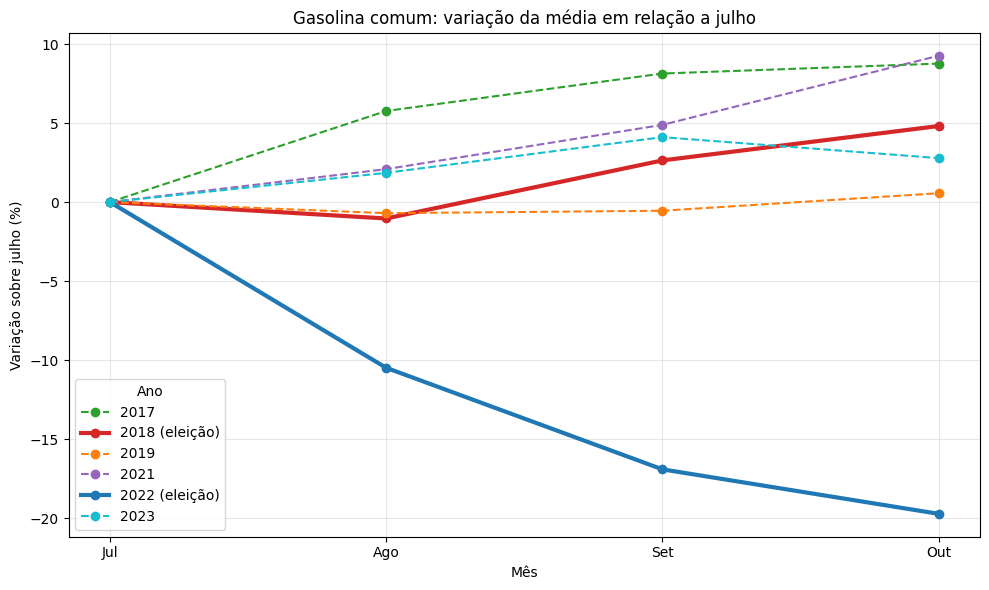

<Figure size 640x480 with 0 Axes>

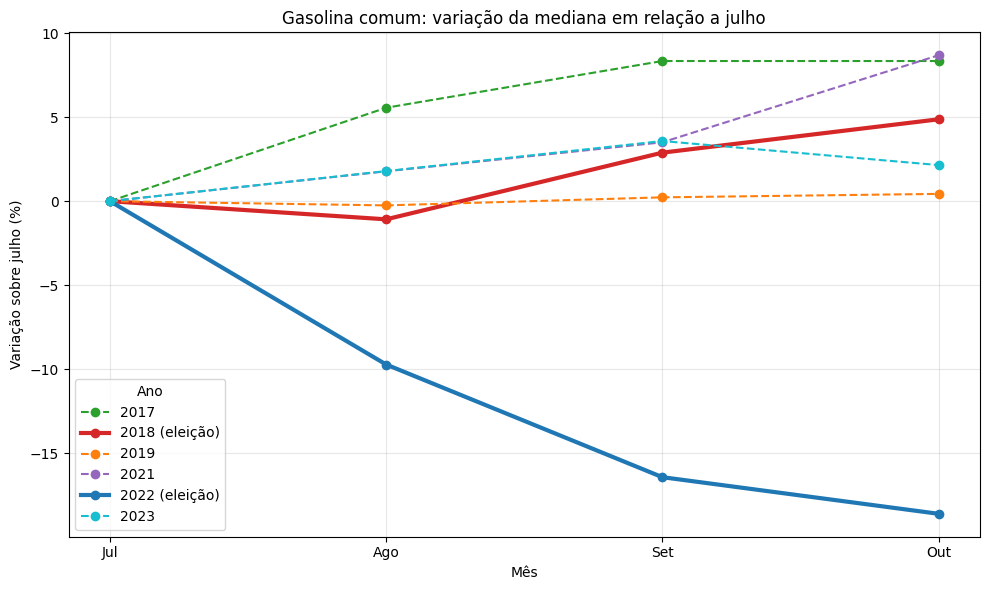

<Figure size 640x480 with 0 Axes>

In [26]:
media_mensal = calcular_preco_mensal(gasolina, "mean")
mediana_mensal = calcular_preco_mensal(gasolina, "median")

plotar_linhas(
    calcular_variacao_sobre_julho(media_mensal),
    "Gasolina comum: variação da média em relação a julho",
    "Variação sobre julho (%)",
)
plotar_linhas(
    calcular_variacao_sobre_julho(mediana_mensal),
    "Gasolina comum: variação da mediana em relação a julho",
    "Variação sobre julho (%)",
)

In [27]:
def filtrar_municipios_em_todos_os_meses(tabela: pd.DataFrame) -> pd.DataFrame:
    meses_com_coleta = tabela.groupby(
        ["ano", COLUNA_ESTADO, COLUNA_MUNICIPIO]
    )["mes"].transform("nunique")
    return tabela[meses_com_coleta == len(MESES_ANALISE)].copy()

Linhas mantidas: 474,452 de 502,308
          registros  postos  municipios
ano  mes                               
2017 7        22391    8641         460
     8        14828    7385         460
     9        12504    7229         460
     10       15364    7581         460
2018 7        25548    9646         461
     8        26543    9843         461
     9        23143    9544         461
     10       27717    9697         461
2019 7        28070   10145         460
     8        24153    9988         460
     9        25043   10208         460
     10       27199   10255         460
2021 7        17506    7731         340
     8        19648    7866         340
     9        18780    7637         340
     10       17825    7603         340
2022 7        13249    5689         199
     8        15918    5980         199
     9         7737    5039         199
     10        8823    4158         199
2023 7        20758    6792         458
     8        21314    6727         458
    

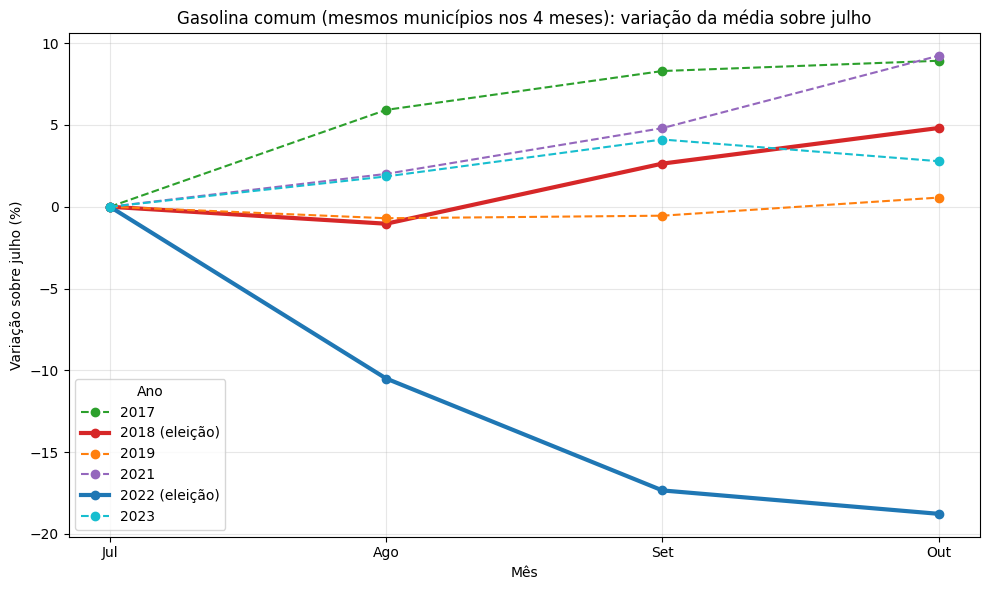

<Figure size 640x480 with 0 Axes>

In [28]:
gasolina_balanceada = filtrar_municipios_em_todos_os_meses(gasolina)
print(f"Linhas mantidas: {len(gasolina_balanceada):,} de {len(gasolina):,}")
print(resumir_amostra(gasolina_balanceada))

media_balanceada = calcular_preco_mensal(gasolina_balanceada, "mean")
print(media_balanceada.round(3))

plotar_linhas(
    calcular_variacao_sobre_julho(media_balanceada),
    "Gasolina comum (mesmos municípios nos 4 meses): variação da média sobre julho",
    "Variação sobre julho (%)",
)